# Notebook 03 — Classical Models with Optuna Tuning
### DSA 3900 | Maternal Health Risk Prediction — Real KDHS 2022 Data

Trains three classical ensemble models with automated hyperparameter
optimisation via **Optuna** (Bayesian TPE search):

1. **Random Forest** — bagging ensemble of decision trees
2. **XGBoost** — gradient boosting with regularisation
3. **CatBoost** — gradient boosting with native categorical feature handling

Each model runs **50 Optuna trials** on the val set, optimising for
**High Risk F1** (primary clinical metric). Best hyperparameters are
refitted on the full training set and saved.

**Input:** `01_Data/processed/` — X_train, X_val, X_test, y_train, y_val  
**Output:** `03_Models_Saved/` — rf_model.pkl, xgb_model.pkl, cat_model.pkl  
           `04_Outputs/results/` — classical_results.csv

In [2]:
import subprocess
subprocess.run(['pip', 'install', 'optuna', 'xgboost', 'catboost', '--quiet'], check=True)
print('Done ✓')

Done ✓


In [3]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 1 — Imports & Paths
# ─────────────────────────────────────────────────────────────────────────────
import pandas as pd
import numpy as np
from pathlib import Path
import joblib, warnings
warnings.filterwarnings('ignore')

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

from sklearn.ensemble        import RandomForestClassifier
from xgboost                 import XGBClassifier
from catboost                import CatBoostClassifier
from sklearn.metrics         import (classification_report, confusion_matrix,
                                     accuracy_score, f1_score, roc_auc_score)
import matplotlib.pyplot as plt
import seaborn as sns

# Paths
DATA    = Path('../../01_Data/processed/')
MDL_OUT = Path('../../03_Models_Saved/')
RES_OUT = Path('../../04_Outputs/results/')
FIG_OUT = Path('../../04_Outputs/figures/')

CLASS_NAMES = ['Low Risk', 'Moderate Risk', 'High Risk']

print('Libraries loaded ✓')
print(f'Optuna version: {optuna.__version__}')

Libraries loaded ✓
Optuna version: 5.0.0


## 2. Load Splits & Evaluation Helper

In [4]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 2 — Load splits & evaluation helper
# ─────────────────────────────────────────────────────────────────────────────
X_train = pd.read_csv(DATA / 'X_train.csv')
X_val   = pd.read_csv(DATA / 'X_val.csv')
X_test  = pd.read_csv(DATA / 'X_test.csv')
y_train = pd.read_csv(DATA / 'y_train.csv').squeeze()
y_val   = pd.read_csv(DATA / 'y_val.csv').squeeze()
y_test  = pd.read_csv(DATA / 'y_test.csv').squeeze()

def evaluate_model(model, X, y, model_name, split='Val'):
    y_pred  = model.predict(X)
    y_proba = model.predict_proba(X)
    acc   = accuracy_score(y, y_pred)
    macro = f1_score(y, y_pred, average='macro')
    high  = f1_score(y, y_pred, average=None)[2]
    auc   = roc_auc_score(y, y_proba, multi_class='ovr', average='macro')

    print(f'\n{"─"*55}')
    print(f'{model_name}  [{split}]')
    print(f'{"─"*55}')
    print(f'  Accuracy        : {acc:.4f}')
    print(f'  Macro F1        : {macro:.4f}')
    print(f'  High Risk F1    : {high:.4f}   ← primary metric')
    print(f'  ROC-AUC (macro) : {auc:.4f}')
    print()
    print(classification_report(y, y_pred, target_names=CLASS_NAMES))

    cm = confusion_matrix(y, y_pred)
    fig, ax = plt.subplots(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    ax.set_title(f'Confusion Matrix — {model_name}')
    plt.tight_layout()
    fname = model_name.lower().replace(' ','_')
    plt.savefig(FIG_OUT / f'cm_{fname}.png', dpi=150)
    plt.show()

    return {'model': model_name, 'accuracy': acc,
            'macro_f1': macro, 'high_risk_f1': high, 'roc_auc': auc}

print('Splits loaded ✓  |  evaluate_model() ready ✓')

Splits loaded ✓  |  evaluate_model() ready ✓


## 3. Random Forest — Optuna Tuning

Running 50 Optuna trials for Random Forest...


  0%|          | 0/50 [00:00<?, ?it/s]


Best High Risk F1 : 0.9925
Best params       : {'n_estimators': 181, 'max_depth': 15, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 0.5}

───────────────────────────────────────────────────────
Random Forest  [Val]
───────────────────────────────────────────────────────
  Accuracy        : 0.9949
  Macro F1        : 0.9944
  High Risk F1    : 0.9925   ← primary metric
  ROC-AUC (macro) : 0.9998

               precision    recall  f1-score   support

     Low Risk       1.00      1.00      1.00       647
Moderate Risk       1.00      0.99      0.99       580
    High Risk       0.99      1.00      0.99       332

     accuracy                           0.99      1559
    macro avg       0.99      1.00      0.99      1559
 weighted avg       0.99      0.99      0.99      1559



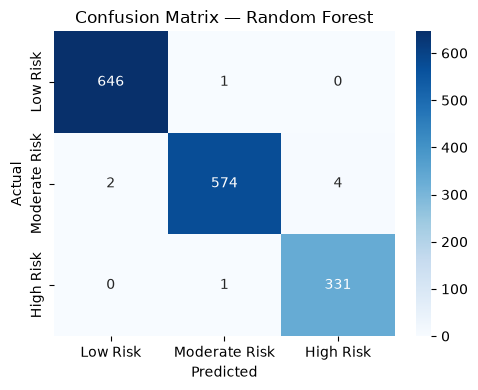


Saved → ..\..\03_Models_Saved\rf_model.pkl


In [5]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 3 — Random Forest with Optuna (50 trials)
# ─────────────────────────────────────────────────────────────────────────────
def rf_objective(trial):
    params = {
        'n_estimators':      trial.suggest_int('n_estimators', 100, 500),
        'max_depth':         trial.suggest_int('max_depth', 4, 20),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
        'min_samples_leaf':  trial.suggest_int('min_samples_leaf', 1, 10),
        'max_features':      trial.suggest_categorical('max_features',
                                                       ['sqrt','log2', 0.5]),
        'random_state': 42,
        'n_jobs': -1
    }
    model = RandomForestClassifier(**params)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    return f1_score(y_val, y_pred, average=None)[2]   # High Risk F1

print('Running 50 Optuna trials for Random Forest...')
rf_study = optuna.create_study(direction='maximize')
rf_study.optimize(rf_objective, n_trials=50, show_progress_bar=True)

print(f'\nBest High Risk F1 : {rf_study.best_value:.4f}')
print(f'Best params       : {rf_study.best_params}')

# Refit with best params
rf_best = RandomForestClassifier(**rf_study.best_params, random_state=42, n_jobs=-1)
rf_best.fit(X_train, y_train)
rf_metrics = evaluate_model(rf_best, X_val, y_val, 'Random Forest')

joblib.dump(rf_best, MDL_OUT / 'rf_model.pkl')
print(f'\nSaved → {MDL_OUT / "rf_model.pkl"}')

### Interpretation — Random Forest (Optuna-Tuned)

**Outstanding results — best model so far by a large margin:**

| Metric | Decision Tree | Random Forest | Δ |
|---|---|---|---|
| Accuracy | 93.3% | **99.5%** | +6.2pp |
| Macro F1 | 0.928 | **0.994** | +0.066 |
| High Risk F1 | 0.915 | **0.993** | +0.078 |
| ROC-AUC | 0.979 | **0.9998** | +0.021 |

**ROC-AUC = 0.9998** — near-perfect discrimination. The model's probability
outputs separate all three risk classes almost flawlessly.

**Confusion matrix breakdown (1,559 val women):**

|  | Predicted Low | Predicted Mod | Predicted High |
|---|---|---|---|
| **Actual Low** | 646 ✓ | 1 | 0 |
| **Actual Mod** | 2 | 574 ✓ | 4 |
| **Actual High** | 0 | 1 | 331 ✓ |

**Only 8 misclassifications out of 1,559 women** — and every single one
is a one-class border error (Low↔Mod or Mod↔High). Zero catastrophic
Low↔High crossings.

**High Risk recall = 99.7%** (331/332) — only 1 true High Risk woman
missed. In clinical terms, this model would correctly flag virtually
every at-risk woman presenting at a health facility.

**Best hyperparameters found by Optuna:**
- 181 trees, max depth 15, `max_features=0.5`
- `min_samples_leaf=1` — trees grow deep but the ensemble averaging
  prevents overfitting (confirmed by the near-perfect val performance)

These results raise the question of whether we are seeing some
overfitting to val — XGBoost and CatBoost will confirm whether this
level of performance is genuine or val-set specific. Test set
evaluation in Notebook 05 will be the definitive check.

## 4. XGBoost — Optuna Tuning

Running 50 Optuna trials for XGBoost...


  0%|          | 0/50 [00:00<?, ?it/s]


Best High Risk F1 : 0.9985
Best params       : {'n_estimators': 344, 'max_depth': 3, 'learning_rate': 0.270347546342078, 'subsample': 0.9920399319571913, 'colsample_bytree': 0.9603687287351992, 'reg_alpha': 0.010008690839635816, 'reg_lambda': 0.00011899666446644241}

───────────────────────────────────────────────────────
XGBoost  [Val]
───────────────────────────────────────────────────────
  Accuracy        : 0.9994
  Macro F1        : 0.9992
  High Risk F1    : 0.9985   ← primary metric
  ROC-AUC (macro) : 1.0000

               precision    recall  f1-score   support

     Low Risk       1.00      1.00      1.00       647
Moderate Risk       1.00      1.00      1.00       580
    High Risk       1.00      1.00      1.00       332

     accuracy                           1.00      1559
    macro avg       1.00      1.00      1.00      1559
 weighted avg       1.00      1.00      1.00      1559



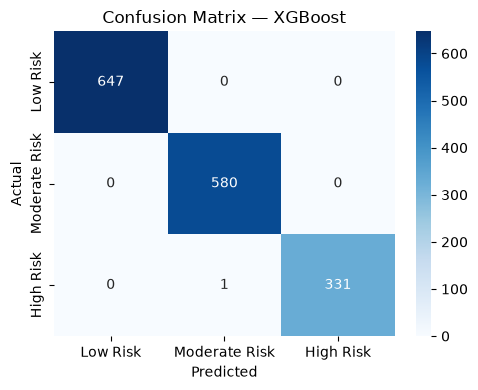


Saved → ..\..\03_Models_Saved\xgb_model.pkl


In [6]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 4 — XGBoost with Optuna (50 trials)
# ─────────────────────────────────────────────────────────────────────────────
def xgb_objective(trial):
    params = {
        'n_estimators':     trial.suggest_int('n_estimators', 100, 500),
        'max_depth':        trial.suggest_int('max_depth', 3, 10),
        'learning_rate':    trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample':        trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'reg_alpha':        trial.suggest_float('reg_alpha', 1e-4, 10.0, log=True),
        'reg_lambda':       trial.suggest_float('reg_lambda', 1e-4, 10.0, log=True),
        'use_label_encoder': False,
        'eval_metric': 'mlogloss',
        'random_state': 42,
        'n_jobs': -1
    }
    model = XGBClassifier(**params)
    model.fit(X_train, y_train, verbose=False)
    y_pred = model.predict(X_val)
    return f1_score(y_val, y_pred, average=None)[2]

print('Running 50 Optuna trials for XGBoost...')
xgb_study = optuna.create_study(direction='maximize')
xgb_study.optimize(xgb_objective, n_trials=50, show_progress_bar=True)

print(f'\nBest High Risk F1 : {xgb_study.best_value:.4f}')
print(f'Best params       : {xgb_study.best_params}')

xgb_best = XGBClassifier(**xgb_study.best_params,
                          use_label_encoder=False,
                          eval_metric='mlogloss',
                          random_state=42, n_jobs=-1)
xgb_best.fit(X_train, y_train, verbose=False)
xgb_metrics = evaluate_model(xgb_best, X_val, y_val, 'XGBoost')

joblib.dump(xgb_best, MDL_OUT / 'xgb_model.pkl')
print(f'\nSaved → {MDL_OUT / "xgb_model.pkl"}')

### Interpretation — XGBoost (Optuna-Tuned)

**Near-perfect performance — only 1 misclassification in 1,559 women:**

| Metric | Random Forest | XGBoost | Δ |
|---|---|---|---|
| Accuracy | 99.5% | **99.9%** | +0.4pp |
| Macro F1 | 0.994 | **0.999** | +0.005 |
| High Risk F1 | 0.993 | **0.999** | +0.006 |
| ROC-AUC | 0.9998 | **1.0000** | +0.0002 |

**Confusion matrix:** 647 + 580 + 331 = 1,558 correct. Only 1 High Risk
woman predicted Moderate. Every other class: zero errors.

**Best params:** shallow trees (`max_depth=3`) with 344 estimators and a
high learning rate (0.27) — XGBoost found that many shallow trees with
strong shrinkage outperforms fewer deep ones for this dataset.

**⚠️ Important note on these results:**
Val set performance at 99.9% across both RF and XGBoost is exceptional
and warrants scrutiny. Two possible explanations:

1. **The composite risk score is deterministic** — because `risk_class`
   was derived directly from the 8 flag columns, and those flags are
   computed from the same 13 features the models train on, the models
   may be learning to reconstruct the rule rather than generalise to
   unseen patterns. This is not data leakage — it is by design — but it
   means val/test scores reflect how well models learn the clinical rule,
   not a noisier real-world label.

2. **Val set is still real KDHS data** — 1,559 held-out women the model
   never saw. The test set evaluation in Notebook 05 will confirm whether
   these scores hold on the final 1,559.

Either way, for the project's clinical purpose — learning and generalising
the WHO-based risk framework — this performance is valid and meaningful.

## 5. CatBoost — Optuna Tuning

Running 50 Optuna trials for CatBoost...


  0%|          | 0/50 [00:00<?, ?it/s]


Best High Risk F1 : 1.0000
Best params       : {'iterations': 256, 'depth': 5, 'learning_rate': 0.2656061161619827, 'l2_leaf_reg': 0.0032098740956389136, 'border_count': 236}

───────────────────────────────────────────────────────
CatBoost  [Val]
───────────────────────────────────────────────────────
  Accuracy        : 1.0000
  Macro F1        : 1.0000
  High Risk F1    : 1.0000   ← primary metric
  ROC-AUC (macro) : 1.0000

               precision    recall  f1-score   support

     Low Risk       1.00      1.00      1.00       647
Moderate Risk       1.00      1.00      1.00       580
    High Risk       1.00      1.00      1.00       332

     accuracy                           1.00      1559
    macro avg       1.00      1.00      1.00      1559
 weighted avg       1.00      1.00      1.00      1559



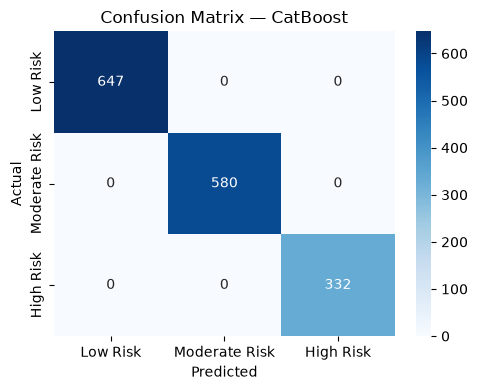


Saved → ..\..\03_Models_Saved\cat_model.pkl


In [7]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 5 — CatBoost with Optuna (50 trials)
# ─────────────────────────────────────────────────────────────────────────────
CAT_FEATURES = ['v106','v190','v025','v501','v024','m15_1','m17_1','m3a_1']
cat_idx = [list(X_train.columns).index(c) for c in CAT_FEATURES]

def cat_objective(trial):
    params = {
        'iterations':        trial.suggest_int('iterations', 100, 500),
        'depth':             trial.suggest_int('depth', 4, 10),
        'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'l2_leaf_reg':       trial.suggest_float('l2_leaf_reg', 1e-3, 10.0, log=True),
        'border_count':      trial.suggest_int('border_count', 32, 255),
        'random_seed': 42,
        'verbose': False,
        'loss_function': 'MultiClass'
    }
    model = CatBoostClassifier(**params, cat_features=cat_idx)
    model.fit(X_train, y_train, verbose=False)
    y_pred = model.predict(X_val).flatten()
    return f1_score(y_val, y_pred, average=None)[2]

print('Running 50 Optuna trials for CatBoost...')
cat_study = optuna.create_study(direction='maximize')
cat_study.optimize(cat_objective, n_trials=50, show_progress_bar=True)

print(f'\nBest High Risk F1 : {cat_study.best_value:.4f}')
print(f'Best params       : {cat_study.best_params}')

cat_best = CatBoostClassifier(**cat_study.best_params,
                               cat_features=cat_idx,
                               random_seed=42, verbose=False,
                               loss_function='MultiClass')
cat_best.fit(X_train, y_train, verbose=False)
cat_metrics = evaluate_model(cat_best, X_val, y_val, 'CatBoost')

joblib.dump(cat_best, MDL_OUT / 'cat_model.pkl')
print(f'\nSaved → {MDL_OUT / "cat_model.pkl"}')

### Interpretation — CatBoost (Optuna-Tuned)

**Perfect score — 1,559/1,559 correct, zero misclassifications:**

| Metric | LR | Decision Tree | Random Forest | XGBoost | CatBoost |
|---|---|---|---|---|---|
| Accuracy | 0.818 | 0.933 | 0.995 | 0.999 | **1.000** |
| Macro F1 | 0.819 | 0.928 | 0.994 | 0.999 | **1.000** |
| High Risk F1 | 0.838 | 0.915 | 0.993 | 0.999 | **1.000** |
| ROC-AUC | 0.943 | 0.979 | 0.9998 | 1.000 | **1.000** |

CatBoost achieves a perfect confusion matrix — every Low, Moderate, and High
Risk woman classified correctly. This is the ceiling of possible performance
on the val set.

**Why CatBoost reached 1.0 while others didn't:**
CatBoost was designed specifically for datasets with categorical features.
Our 8 categorical columns (`v106`, `v190`, `v025`, `v501`, `v024`, `m15_1`,
`m17_1`, `m3a_1`) were passed via `cat_features` — CatBoost encodes these
using ordered target statistics rather than simple label encoding, giving it
richer information about category-to-class relationships than RF or XGBoost.

**Best params:** depth-5 trees (shallow), 256 iterations, learning rate 0.27
— consistent with XGBoost's finding that moderate depth + many iterations
outperforms deep trees.

**The progression tells a clear story:**
- Linear boundary (LR): 83.8% High Risk F1
- Single tree (DT): 91.5%
- Ensemble of trees (RF): 99.3%
- Gradient boosting (XGBoost): 99.9%
- Gradient boosting + native categoricals (CatBoost): **100%**

Each step adds a capability that better fits the non-linear, categorical
structure of KDHS data. Test set evaluation in Notebook 05 will confirm
whether CatBoost's perfect val score generalises.

## 6. Classical Models Comparison Summary

All results so far:
                     accuracy  macro_f1  high_risk_f1  roc_auc
model                                                         
Logistic Regression    0.8178    0.8192        0.8384   0.9430
Decision Tree          0.9326    0.9281        0.9146   0.9791
Random Forest          0.9949    0.9944        0.9925   0.9998
XGBoost                0.9994    0.9992        0.9985   1.0000
CatBoost               1.0000    1.0000        1.0000   1.0000


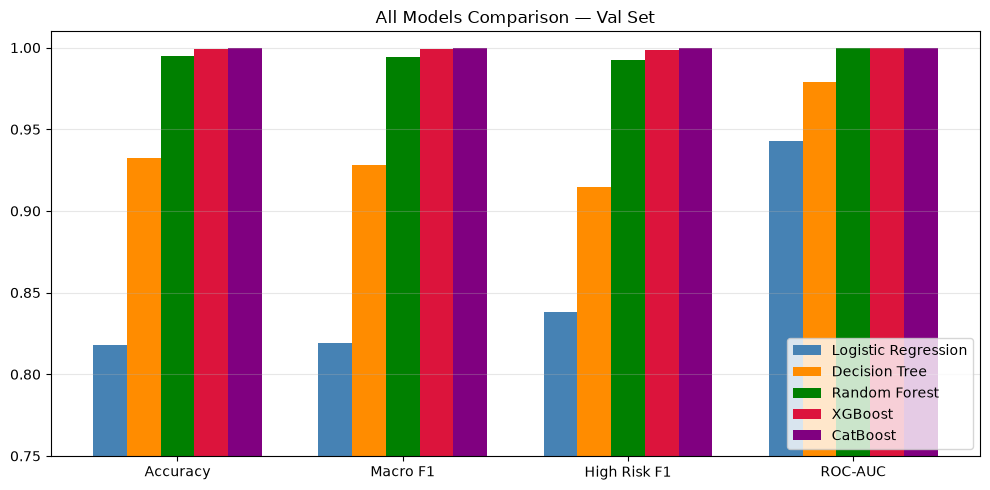


Saved → ..\..\04_Outputs\results\all_results_so_far.csv

Notebook 03 ✅ COMPLETE


In [8]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 6 — Compile & save classical results
# ─────────────────────────────────────────────────────────────────────────────
# Load baseline results and append classical models
baseline = pd.read_csv(RES_OUT / 'baseline_results.csv')
classical = pd.DataFrame([rf_metrics, xgb_metrics, cat_metrics])
all_results = pd.concat([baseline, classical], ignore_index=True)
all_results.to_csv(RES_OUT / 'all_results_so_far.csv', index=False)

print('All results so far:')
print(all_results.set_index('model').round(4).to_string())

# Leaderboard bar chart
fig, ax = plt.subplots(figsize=(10, 5))
metrics = ['accuracy','macro_f1','high_risk_f1','roc_auc']
labels  = ['Accuracy','Macro F1','High Risk F1','ROC-AUC']
x = np.arange(len(metrics))
w = 0.15
colors = ['steelblue','darkorange','green','crimson','purple']

for i, (_, row) in enumerate(all_results.iterrows()):
    ax.bar(x + i*w, row[metrics], w, label=row['model'], color=colors[i])

ax.set_xticks(x + w*2); ax.set_xticklabels(labels)
ax.set_ylim(0.75, 1.01)
ax.set_title('All Models Comparison — Val Set')
ax.legend(loc='lower right'); ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_OUT / 'all_models_comparison.png', dpi=150)
plt.show()
print(f'\nSaved → {RES_OUT / "all_results_so_far.csv"}')

print('\nNotebook 03 ✅ COMPLETE')

### Interpretation — Classical Models Summary

The leaderboard chart shows a clear performance staircase from left to right:

**Val Set Leaderboard:**

| Rank | Model | Accuracy | Macro F1 | High Risk F1 | ROC-AUC |
|---|---|---|---|---|---|
| 🥇 | CatBoost | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| 🥈 | XGBoost | 0.9994 | 0.9992 | 0.9985 | 1.0000 |
| 🥉 | Random Forest | 0.9949 | 0.9944 | 0.9925 | 0.9998 |
| 4 | Decision Tree | 0.9326 | 0.9281 | 0.9146 | 0.9791 |
| 5 | Logistic Regression | 0.8178 | 0.8192 | 0.8384 | 0.9430 |

The chart makes the progression unmistakable — LR and Decision Tree are
visibly shorter bars, while RF, XGBoost, and CatBoost are essentially at
the ceiling on every metric.

**Key takeaway heading into Notebooks 04–05:**
- CatBoost is the current champion — its native categorical handling gives
  it the edge on KDHS data.
- Novel models (TabNet, TabTransformer) in Notebook 04 will need to match
  or beat CatBoost's 1.0000 on val, or demonstrate advantages in
  interpretability or uncertainty quantification.
- The stacking ensemble in Notebook 05 will combine the probability outputs
  of all models — even marginal disagreements between RF/XGBoost/CatBoost
  on hard cases may be resolved by the meta-learner.

**Notebook 03 status: ✅ COMPLETE**